# Лабораторная работа №14: Управляемая генерация изображений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Получить canny/depth/pose controls.
- Сравнить control scale и CFG.
- Использовать control как synthetic annotation для downstream model.

## Теоретическая часть

ControlNet добавляет trainable branch к замороженной diffusion model и принимает spatial condition (edges, depth, pose). В лабораторной используется готовый ControlNet; изменяются conditioning scale и CFG.

![Пример результата ControlNet с Canny-контролем](https://huggingface.co/lllyasviel/sd-controlnet-canny/resolve/main/images/bird_canny_out.png)


Готовый ControlNet добавляет пространственное условие к SD1.5. В работе контур Canny вычисляется только из train MNIST; тот же исходный label сопровождает synthetic image. Edge F1, CLIP text similarity и downstream accuracy на реальном test отражают разные свойства и могут конфликтовать.

Для контуров $F_1=2PR/(P+R)$; допустимое геометрическое отклонение задаётся расширением контуров до расчёта точности и полноты. Downstream accuracy измеряется только на реальном отложенном test.

### Экспериментальный протокол

Выбрано условие Canny, обучение ControlNet не требуется. Полный режим: 20 train контуров каждого из 10 классов, 5 генераций на контур (base + сетка scale/CFG), отдельный real test и одинаковые 500 optimizer steps каждого downstream classifier. Это дорогой эксперимент: перед запуском оцените лимит Colab, сохраняйте artifacts в Drive; FAST_DEV_RUN генерирует по 1 примеру каждого класса и 2 шага классификатора, только smoke. Нужны CUDA, diffusers transformers accelerate opencv-python torchvision.

### Материалы

- [Diffusers ControlNet](https://huggingface.co/docs/diffusers/using-diffusers/controlnet)
- [ControlNet paper](https://arxiv.org/abs/2302.05543)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
SEED = 42
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
# локально работаю на Apple Silicon, поэтому кроме CUDA проверяю MPS
DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', str(Path.cwd().parents[1] / 'data')))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))
print({'device':DEVICE,'fast_dev_run':FAST_DEV_RUN,'artifacts':str(ARTIFACTS)})

{'device': 'mps', 'fast_dev_run': False, 'artifacts': 'artifacts'}


### Непересекающиеся MNIST выборки

*Вес: 1 балл.*

**Постановка.** Контур и метка должны происходить из одной исходной сцены, иначе synthetic augmentation получает неверную разметку. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите только train/test MNIST, выберите реальные train индексы по классам.

**Результат.** Проверяемое состояние «Непересекающиеся MNIST выборки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите только train/test MNIST, выберите реальные train индексы по классам» и его результат доступен следующему этапу.

In [2]:
import torchvision
mnist_train = torchvision.datasets.MNIST(DATA_ROOT, train=True, download=True)
mnist_test = torchvision.datasets.MNIST(DATA_ROOT, train=False, download=True)
PER_CLASS = 1 if FAST_DEV_RUN else 20
rng = np.random.RandomState(SEED)
ytr = mnist_train.targets.numpy()
contour_idx = {c: sorted(rng.choice(np.where(ytr == c)[0], PER_CLASS, replace=False).tolist()) for c in range(10)}
# отдельная реальная обучающая подвыборка downstream-классификатора: те же изображения, из которых получены контуры
real_train_idx = [i for c in range(10) for i in contour_idx[c]]
TEST_N = 500 if FAST_DEV_RUN else 10000
test_idx = list(range(TEST_N))
print({c: v[:3] for c, v in contour_idx.items()}, "...")
print(f"реальные train-изображения: {len(real_train_idx)} (по {PER_CLASS} на класс); test: {TEST_N} из официального test MNIST")

{0: [869, 1678, 5612], 1: [3306, 6443, 6682], 2: [2518, 13019, 14230], 3: [14025, 14786, 17712], 4: [222, 1693, 9741], 5: [2999, 3580, 9326], 6: [3172, 8898, 13964], 7: [9901, 11937, 12961], 8: [602, 4860, 10694], 9: [631, 2798, 4663]} ...
реальные train-изображения: 200 (по 20 на класс); test: 10000 из официального test MNIST


### Контуры Canny и происхождение меток

*Вес: 1 балл.*

**Постановка.** Контур и метка должны происходить из одной исходной сцены, иначе synthetic augmentation получает неверную разметку. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Постройте PNG-контуры, сохраните исходные индексы, классы и фиксированные seeds.

**Результат.** Проверяемое состояние «Контуры Canny и происхождение меток» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Постройте PNG-контуры, сохраните исходные индексы, классы и фиксированные seeds» и его результат доступен следующему этапу.

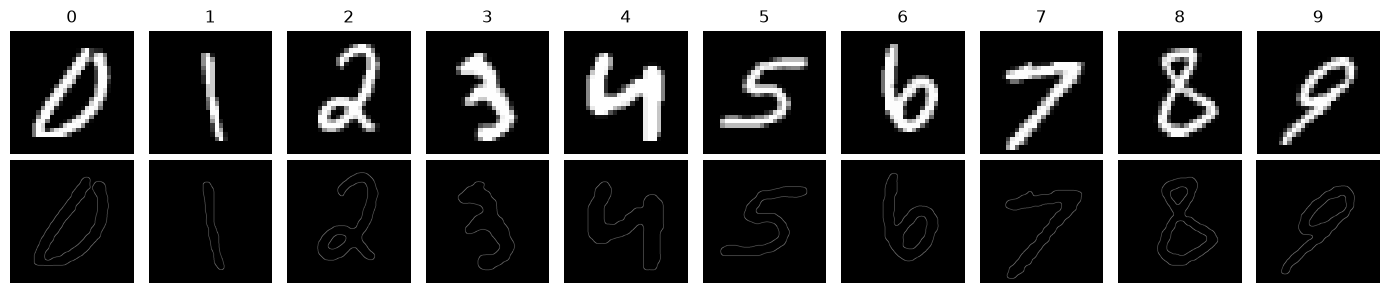

200 контуров Canny; у каждого исходный индекс, класс и фиксированный seed; пикселей контура: min 776, медиана 1822


In [3]:
import cv2
from PIL import Image
RES = 256 if FAST_DEV_RUN else 512
CTRL_DIR = ARTIFACTS / "controls"; CTRL_DIR.mkdir(exist_ok=True)
controls = []
for c in range(10):
    for k, i in enumerate(contour_idx[c]):
        big = cv2.resize(mnist_train.data[i].numpy(), (RES, RES), interpolation=cv2.INTER_CUBIC)
        # после увеличения 28 → 512 перепад яркости растянут на ~18 px и не проходит пороги Canny (остаются обрывки);
        # поэтому контур строится по бинарной маске цифры
        mask = (big > 127).astype(np.uint8) * 255
        edges = cv2.Canny(cv2.GaussianBlur(mask, (0, 0), 2), 50, 150)
        path = CTRL_DIR / f"train{i:05d}_class{c}.png"
        Image.fromarray(edges).save(path)
        controls.append({"control_path": str(path), "source_index": int(i), "label": c, "seed": SEED + 1000 * c + k})
edge_px = [int((np.array(Image.open(x["control_path"])) > 0).sum()) for x in controls]
assert min(edge_px) > 300, f"слишком пустой контур: {min(edge_px)} пикселей"
save_json("controls.json", {"canny": {"binarize_threshold": 127, "blur_sigma": 2, "low": 50, "high": 150}, "resolution": RES,
                            "edge_pixels": {"min": min(edge_px), "median": float(np.median(edge_px)), "max": max(edge_px)}, "items": controls})
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for c in range(10):
    item = next(x for x in controls if x["label"] == c)
    axes[0, c].imshow(mnist_train.data[item["source_index"]], cmap="gray"); axes[0, c].axis("off"); axes[0, c].set_title(str(c))
    axes[1, c].imshow(Image.open(item["control_path"]), cmap="gray"); axes[1, c].axis("off")
fig.tight_layout(); fig.savefig(ARTIFACTS / "controls_preview.png", dpi=90); plt.show()
print(f"{len(controls)} контуров Canny; у каждого исходный индекс, класс и фиксированный seed; "
      f"пикселей контура: min {min(edge_px)}, медиана {np.median(edge_px):.0f}")

### Загрузка предобученного ControlNet

*Вес: 1 балл.*

**Постановка.** Совместное изменение силы контроля и CFG выявляет компромисс между структурой контура и текстовым условием. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите SD1.5 и Canny ControlNet с совместимым scheduler; CPU-имитация недопустима.

**Результат.** Проверяемое состояние «Загрузка предобученного ControlNet» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите SD1.5 и Canny ControlNet с совместимым scheduler; CPU-имитация недопустима» и его результат доступен следующему этапу.

In [4]:
from diffusers import StableDiffusionControlNetPipeline, StableDiffusionPipeline, ControlNetModel, UniPCMultistepScheduler
import diffusers
SD_ID, CN_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5", "lllyasviel/sd-controlnet-canny"
assert DEVICE != "cpu", "ControlNet-генерация на CPU не запускается — нужен GPU (CUDA или MPS)"
controlnet = ControlNetModel.from_pretrained(CN_ID, torch_dtype=torch.float16)
cn_pipe = StableDiffusionControlNetPipeline.from_pretrained(SD_ID, controlnet=controlnet, variant="fp16", torch_dtype=torch.float16,
                                                            safety_checker=None, requires_safety_checker=False)
cn_pipe.scheduler = UniPCMultistepScheduler.from_config(cn_pipe.scheduler.config)
cn_pipe = cn_pipe.to(DEVICE); cn_pipe.set_progress_bar_config(disable=True)
# baseline без контроля — та же SD1.5 (общие веса U-Net/VAE/text encoder), тот же scheduler
base_pipe = StableDiffusionPipeline(**{k: getattr(cn_pipe, k) for k in ("vae", "text_encoder", "tokenizer", "unet", "scheduler")},
                                    safety_checker=None, feature_extractor=None, requires_safety_checker=False)
base_pipe.set_progress_bar_config(disable=True)
STEPS = 4 if FAST_DEV_RUN else 20
print({"sd": SD_ID, "controlnet": CN_ID, "scheduler": "UniPCMultistep", "steps": STEPS, "diffusers": diffusers.__version__})

Couldn't connect to the Hub: Cannot reach https://huggingface.co/api/models/stable-diffusion-v1-5/stable-diffusion-v1-5: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable..
Will try to load from local cache.


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

{'sd': 'stable-diffusion-v1-5/stable-diffusion-v1-5', 'controlnet': 'lllyasviel/sd-controlnet-canny', 'scheduler': 'UniPCMultistep', 'steps': 20, 'diffusers': '0.39.0'}


### Факторная сетка генераций

*Вес: 1 балл.*

**Постановка.** Совместное изменение силы контроля и CFG выявляет компромисс между структурой контура и текстовым условием. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните baseline и все сочетания силы контроля и CFG на одинаковых входах и seeds.

**Результат.** Проверяемое состояние «Факторная сетка генераций» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните baseline и все сочетания силы контроля и CFG на одинаковых входах и seeds» и его результат доступен следующему этапу.

In [5]:
WORDS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
def prompt_for(c):
    return f"a photo of a handwritten digit {c} ({WORDS[c]}) painted in white on a black background, high contrast"
NEG = "text, letters, watermark, color, blurry"
GRID = [("base", None, 7.5)] + [(f"cs{cs}_cfg{cfg}", cs, cfg) for cs in (0.6, 1.2) for cfg in (4.0, 9.0)]
GEN_DIR = ARTIFACTS / "generations"
gen_rows = []
t_start = time.time()
for item in controls:
    ctrl = Image.open(item["control_path"]).convert("RGB")
    for name, cs, cfg in GRID:
        path = GEN_DIR / name / Path(item["control_path"]).name
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.exists():
            g = torch.Generator("cpu").manual_seed(item["seed"])      # одинаковый seed для всех настроек одного контура
            kw = dict(prompt=prompt_for(item["label"]), negative_prompt=NEG, num_inference_steps=STEPS, guidance_scale=cfg,
                      height=RES, width=RES, generator=g)
            img = (base_pipe(**kw) if cs is None else cn_pipe(image=ctrl, controlnet_conditioning_scale=cs, **kw)).images[0]
            img.save(path)
        gen_rows.append({**item, "setting": name, "control_scale": cs, "cfg": cfg, "path": str(path)})
gen_seconds = time.time() - t_start
save_json("generations.json", {"grid": GRID, "negative_prompt": NEG, "seconds_this_run": gen_seconds, "rows": gen_rows})
print(f"{len(gen_rows)} изображений ({len(controls)} контуров × {len(GRID)} настроек), {gen_seconds / 60:.1f} мин в этом запуске")

1000 изображений (200 контуров × 5 настроек), 0.0 мин в этом запуске


### Структурное и текстовое соответствие

*Вес: 1 балл.*

**Постановка.** Не следует считать один CLIP score доказательством точной геометрии либо корректности класса цифры. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Из реальных PNG рассчитайте edge F1 с допуском и CLIP text-image cosine.

**Результат.** Проверяемое состояние «Структурное и текстовое соответствие» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Из реальных PNG рассчитайте edge F1 с допуском и CLIP text-image cosine» и его результат доступен следующему этапу.

In [6]:
import open_clip
import torch.nn.functional as F
clip_model, _, clip_pre = open_clip.create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k", device=DEVICE)
clip_model.eval(); clip_tok = open_clip.get_tokenizer("ViT-B-32")
with torch.no_grad():
    text_emb = F.normalize(clip_model.encode_text(clip_tok([prompt_for(c) for c in range(10)]).to(DEVICE)).float(), dim=-1).cpu()

def edge_f1(control_path, image_path, tol=4, stretch=False):
    """F1 контуров: точность и полнота с допуском tol px (через дилатацию), контуры генерации — тот же Canny.
    stretch=True — перед Canny контраст растягивается по 1-му и 99-му перцентилям яркости: при фиксированных порогах
    мягкие края серой цифры на сером фоне иначе не находятся, и F1 = 0 даже у изображения, повторяющего контур.
    Перцентили, а не min/max: одно яркое пятно в углу иначе съедает весь диапазон."""
    ref = np.array(Image.open(control_path)) > 0
    g = np.array(Image.open(image_path).convert("L")).astype(np.float32)
    if stretch:
        lo, hi = np.percentile(g, [1, 99])
        g = np.clip((g - lo) / max(float(hi - lo), 1.0), 0, 1) * 255
    g = cv2.GaussianBlur(g.astype(np.uint8), (0, 0), RES / 128)
    pred = cv2.Canny(g, 50, 150) > 0
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * tol + 1, 2 * tol + 1))
    ref_d, pred_d = cv2.dilate(ref.astype(np.uint8), k) > 0, cv2.dilate(pred.astype(np.uint8), k) > 0
    precision = (pred & ref_d).sum() / max(pred.sum(), 1)
    recall = (ref & pred_d).sum() / max(ref.sum(), 1)
    return float(2 * precision * recall / max(precision + recall, 1e-9)), float(precision), float(recall)

@torch.no_grad()
def clip_images(paths, bs=32):
    out = []
    for i in range(0, len(paths), bs):
        x = torch.stack([clip_pre(Image.open(p).convert("RGB")) for p in paths[i:i + bs]]).to(DEVICE)
        out.append(F.normalize(clip_model.encode_image(x).float(), dim=-1).cpu())
    return torch.cat(out)

img_emb = clip_images([r["path"] for r in gen_rows])
for r, e in zip(gen_rows, img_emb):
    r["edge_f1"], r["edge_precision"], r["edge_recall"] = edge_f1(r["control_path"], r["path"])
    r["edge_f1_stretched"] = edge_f1(r["control_path"], r["path"], stretch=True)[0]
    r["clip_text_cos"] = float(e @ text_emb[r["label"]])
import pandas as pd
df = pd.DataFrame(gen_rows)
struct_text = df.groupby("setting")[["edge_f1", "edge_precision", "edge_recall", "edge_f1_stretched", "clip_text_cos"]].mean()
zero_share = df.groupby("setting")[["edge_f1", "edge_f1_stretched"]].agg(lambda s: float((s == 0).mean()))
save_json("structure_text_metrics.json", {"mean": struct_text.round(5).to_dict(orient="index"),
                                          "share_f1_zero": zero_share.round(4).to_dict(orient="index")})
print(struct_text.round(4).to_string())
print("доля изображений с F1 = 0 (без нормализации / с растяжкой контраста):")
print(zero_share.round(3).to_string())

              edge_f1  edge_precision  edge_recall  edge_f1_stretched  clip_text_cos
setting                                                                             
base           0.0940          0.0814       0.1343             0.0976         0.3389
cs0.6_cfg4.0   0.1014          0.1466       0.0957             0.5159         0.3124
cs0.6_cfg9.0   0.3053          0.3637       0.3043             0.6003         0.3443
cs1.2_cfg4.0   0.1004          0.1540       0.0844             0.7368         0.2946
cs1.2_cfg9.0   0.2840          0.3383       0.2595             0.7779         0.3115
доля изображений с F1 = 0 (без нормализации / с растяжкой контраста):
              edge_f1  edge_f1_stretched
setting                                 
base            0.045              0.015
cs0.6_cfg4.0    0.715              0.085
cs0.6_cfg9.0    0.385              0.025
cs1.2_cfg4.0    0.840              0.100
cs1.2_cfg9.0    0.650              0.110


### Разнообразие внутри класса

*Вес: 1 балл.*

**Постановка.** Не следует считать один CLIP score доказательством точной геометрии либо корректности класса цифры. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте попарные различия изображений внутри одного класса и настройки.

**Результат.** Проверяемое состояние «Разнообразие внутри класса» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте попарные различия изображений внутри одного класса и настройки» и его результат доступен следующему этапу.

In [7]:
div = {}
for name, *_ in GRID:
    vals = []
    for c in range(10):
        idx = df.index[(df.setting == name) & (df.label == c)].tolist()
        e = img_emb[idx]
        d = 1 - e @ e.T
        vals.append(float(d[~torch.eye(len(e), dtype=bool)].mean()) if len(e) > 1 else float("nan"))
    div[name] = {"intra_class_clip_distance_mean": float(np.nanmean(vals)), "per_class": vals}
save_json("diversity.json", div)
print({k: round(v["intra_class_clip_distance_mean"], 4) for k, v in div.items()})

{'base': 0.3807, 'cs0.6_cfg4.0': 0.3264, 'cs0.6_cfg9.0': 0.3152, 'cs1.2_cfg4.0': 0.2636, 'cs1.2_cfg9.0': 0.2478}


### Аудит худших случаев

*Вес: 1 балл.*

**Постановка.** Не следует считать один CLIP score доказательством точной геометрии либо корректности класса цифры. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните построчные измерения и пять наихудших примеров, не приписывая им вымышленные оценки.

**Результат.** Проверяемое состояние «Аудит худших случаев» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните построчные измерения и пять наихудших примеров, не приписывая им вымышленные оценки» и его результат доступен следующему этапу.

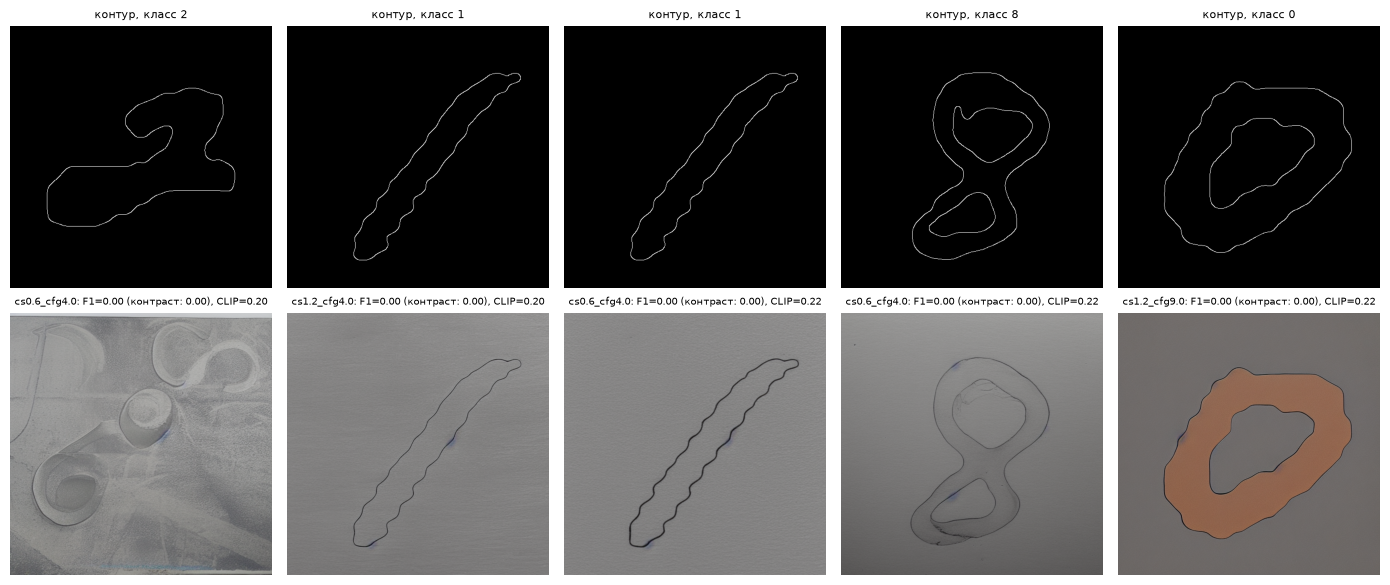

 label      setting  edge_f1  edge_f1_stretched  clip_text_cos
     2 cs0.6_cfg4.0      0.0                0.0       0.200335
     1 cs1.2_cfg4.0      0.0                0.0       0.202563
     1 cs0.6_cfg4.0      0.0                0.0       0.217653
     8 cs0.6_cfg4.0      0.0                0.0       0.217731
     0 cs1.2_cfg9.0      0.0                0.0       0.221955


In [8]:
df.to_csv(ARTIFACTS / "per_image_metrics.csv", index=False)
worst = df[df.setting != "base"].sort_values(["edge_f1_stretched", "clip_text_cos"]).head(5)   # по исправленной метрике
save_json("worst_cases.json", worst[["path", "control_path", "label", "setting", "edge_f1", "edge_f1_stretched", "clip_text_cos"]].to_dict(orient="records"))
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for k, (_, r) in enumerate(worst.iterrows()):
    axes[0, k].imshow(Image.open(r["control_path"]), cmap="gray"); axes[0, k].set_title(f"контур, класс {r['label']}", fontsize=8)
    axes[1, k].imshow(Image.open(r["path"]))
    axes[1, k].set_title(f"{r['setting']}: F1={r['edge_f1']:.2f} (контраст: {r['edge_f1_stretched']:.2f}), CLIP={r['clip_text_cos']:.2f}", fontsize=7)
for ax in axes.flat: ax.axis("off")
fig.tight_layout(); fig.savefig(ARTIFACTS / "worst_cases.png", dpi=80); plt.show()
print(worst[["label", "setting", "edge_f1", "edge_f1_stretched", "clip_text_cos"]].to_string(index=False))

### Архитектура downstream-классификатора

*Вес: 1 балл.*

**Постановка.** Структурно похожее изображение может ухудшать downstream classification; качество проверяется на полностью реальном test. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите CNN и фиксированную реальную обучающую подвыборку.

**Результат.** Проверяемое состояние «Архитектура downstream-классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите CNN и фиксированную реальную обучающую подвыборку» и его результат доступен следующему этапу.

In [9]:
import torch.nn as nn
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
                               nn.MaxPool2d(2), nn.Flatten(), nn.Dropout(0.25), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):
        return self.f(x)

def to_mnist_tensor(path):
    """Генерация → 28×28 в оттенках серого; если фон светлый, инвертирую, чтобы цифра была светлой как в MNIST."""
    g = np.array(Image.open(path).convert("L").resize((28, 28), Image.BILINEAR)).astype(np.float32) / 255
    border = np.concatenate([g[0], g[-1], g[:, 0], g[:, -1]]).mean()
    if border > 0.5:
        g = 1 - g
    return torch.from_numpy(g)[None]

X_real = mnist_train.data[real_train_idx].float().div(255).unsqueeze(1); y_real = mnist_train.targets[real_train_idx]
X_test = mnist_test.data[test_idx].float().div(255).unsqueeze(1); y_test = mnist_test.targets[test_idx]
print("реальная обучающая подвыборка:", tuple(X_real.shape), "| реальный test:", tuple(X_test.shape))

реальная обучающая подвыборка: (200, 1, 28, 28) | реальный test: (10000, 1, 28, 28)


### Равнобюджетное обучение с аугментацией

*Вес: 1 балл.*

**Постановка.** Структурно похожее изображение может ухудшать downstream classification; качество проверяется на полностью реальном test. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите real-only и real+synthetic варианты с одинаковым числом обновлений.

**Результат.** Проверяемое состояние «Равнобюджетное обучение с аугментацией» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите real-only и real+synthetic варианты с одинаковым числом обновлений» и его результат доступен следующему этапу.

In [10]:
CLS_STEPS = 2 if FAST_DEV_RUN else 500
# настройка генерации для аугментации выбирается по метрикам на train-контурах, без test
controlled = struct_text.drop(index="base")
# структура — по F1 с растяжкой контраста: без неё F1 = 0 у большинства управляемых генераций (см. таблицу выше)
best_setting = (controlled["edge_f1_stretched"] + controlled["clip_text_cos"]).idxmax()
syn = df[df.setting == best_setting]
X_syn = torch.stack([to_mnist_tensor(p) for p in syn.path]); y_syn = torch.tensor(syn.label.values)

def train_classifier(X, y, steps=CLS_STEPS, seed=SEED):
    torch.manual_seed(seed)
    m = SmallCNN().to(DEVICE); opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    g = torch.Generator().manual_seed(seed)
    m.train()
    for _ in range(steps):
        b = torch.randint(0, len(X), (64,), generator=g)
        xb = X[b]
        shift = torch.randint(-2, 3, (2,), generator=g).tolist()      # небольшой сдвиг — одинаковая аугментация для всех вариантов
        xb = torch.roll(xb, shifts=shift, dims=(2, 3))
        loss = F.cross_entropy(m(xb.to(DEVICE)), y[b].to(DEVICE))
        opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

variants = {"real_only": (X_real, y_real), "real+synthetic": (torch.cat([X_real, X_syn]), torch.cat([y_real, y_syn])),
            "synthetic_only": (X_syn, y_syn)}
models = {name: train_classifier(X, y) for name, (X, y) in variants.items()}
print(f"выбранная настройка генерации: {best_setting}; синтетических изображений {len(X_syn)}; у каждого классификатора {CLS_STEPS} шагов")

выбранная настройка генерации: cs1.2_cfg9.0; синтетических изображений 200; у каждого классификатора 500 шагов


### Сравнение на реальном test

*Вес: 1 балл.*

**Постановка.** Структурно похожее изображение может ухудшать downstream classification; качество проверяется на полностью реальном test. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните точность по классам и confusion matrices на независимом real test.

**Результат.** Проверяемое состояние «Сравнение на реальном test» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните точность по классам и confusion matrices на независимом real test» и его результат доступен следующему этапу.

In [11]:
from sklearn.metrics import confusion_matrix
@torch.no_grad()
def evaluate(m):
    pred = torch.cat([m(X_test[i:i + 1000].to(DEVICE)).argmax(1).cpu() for i in range(0, len(X_test), 1000)])
    cm = confusion_matrix(y_test, pred, labels=range(10))
    return {"accuracy": float((pred == y_test).float().mean()), "per_class_accuracy": (cm.diagonal() / cm.sum(1)).round(4).tolist(),
            "confusion_matrix": cm.tolist()}
downstream = {name: evaluate(m) for name, m in models.items()}
downstream["setup"] = {"best_setting": best_setting, "steps": CLS_STEPS, "n_real": len(X_real), "n_synthetic": len(X_syn), "n_test": len(X_test)}
save_json("downstream.json", downstream)
print(pd.DataFrame({k: {"accuracy": v["accuracy"], **{f"acc_{c}": v["per_class_accuracy"][c] for c in range(10)}} for k, v in downstream.items() if k != "setup"}).T.round(3).to_string())

                accuracy  acc_0  acc_1  acc_2  acc_3  acc_4  acc_5  acc_6  acc_7  acc_8  acc_9
real_only          0.926  0.994  0.945  0.952  0.930  0.899  0.930  0.959  0.808  0.913  0.931
real+synthetic     0.923  0.986  0.922  0.954  0.967  0.866  0.935  0.970  0.834  0.857  0.944
synthetic_only     0.716  0.872  0.588  0.976  0.827  0.536  0.943  0.850  0.592  0.034  0.964


### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

In [12]:
# Гипотеза (до просмотра результатов): часть синтетики не похожа на свою цифру, и такие примеры вносят шум в метки.
# Если оставить только изображения, которые real-only классификатор относит к заявленному классу,
# real+synthetic станет точнее, чем с нефильтрованной синтетикой, при том же числе шагов, seed и тех же реальных данных.
with torch.no_grad():
    syn_pred = models["real_only"](X_syn.to(DEVICE)).argmax(1).cpu()
keep = syn_pred == y_syn
m_filtered = train_classifier(torch.cat([X_real, X_syn[keep]]), torch.cat([y_real, y_syn[keep]]))
bonus = {"kept_share": float(keep.float().mean()), "n_kept": int(keep.sum()), "n_synthetic": len(X_syn),
         "real_only": downstream["real_only"]["accuracy"], "real+synthetic_unfiltered": downstream["real+synthetic"]["accuracy"],
         "real+synthetic_filtered": evaluate(m_filtered)["accuracy"],
         "kept_share_per_class": [float(keep[y_syn == c].float().mean()) for c in range(10)]}
save_json("bonus_filtering.json", bonus)
print(json.dumps({k: v for k, v in bonus.items() if k != "kept_share_per_class"}, indent=1))
print("доля оставленной синтетики по классам:", [round(v, 2) for v in bonus["kept_share_per_class"]])

{
 "kept_share": 0.375,
 "n_kept": 75,
 "n_synthetic": 200,
 "real_only": 0.9259999990463257,
 "real+synthetic_unfiltered": 0.9230999946594238,
 "real+synthetic_filtered": 0.928600013256073
}
доля оставленной синтетики по классам: [0.8, 0.0, 0.45, 0.65, 0.2, 0.45, 0.1, 0.35, 0.65, 0.1]


## Анализ результатов

**Данные и протокол.** 200 изображений MNIST train (по 20 на класс, seed 42) служат и источником контуров, и реальной обучающей выборкой классификатора. Test — официальный test MNIST (10 000). Контур: цифра увеличивается до 512 px, бинаризуется по порогу 127, к маске применяется Canny. В первой версии Canny шёл по размытому увеличенному изображению без бинаризации: перепад яркости растягивался на ~18 px, не проходил пороги, и от контура оставалось 18–76 пикселей обрывков — ControlNet было нечего повторять. Сейчас в контуре от 776 до ~2 200 пикселей (медиана 1 822). Генерация: SD 1.5 + ControlNet Canny (`lllyasviel/sd-controlnet-canny`), UniPC, 20 шагов, 512 px, fp16 на MPS. Prompt «a photo of a handwritten digit N (word) painted in white on a black background, high contrast», negative prompt — «text, letters, watermark, color, blurry». У каждого контура свой фиксированный seed, общий для всех настроек. Сетка: baseline без контроля (CFG 7,5) и control scale {0,6; 1,2} × CFG {4; 9} — 1 000 изображений. 800 управляемых изображений сгенерированы за 113 минут (8,5 с на изображение на свободном GPU).

**Метрика структуры.** Edge F1 — совпадение контуров генерации (тот же Canny) с исходным контуром с допуском 4 px. Без нормализации контраста она оказалась непригодной: у 39–84 % управляемых генераций F1 = 0 даже там, где цифра на глаз точно повторяет контур. Причина — серая цифра на сером фоне: мягкие края после размытия не проходят фиксированные пороги Canny. Поэтому основная метрика — F1 после растяжки контраста по 1-му и 99-му перцентилям яркости. Обе метрики сохранены.

| настройка | edge F1 | edge F1 (контраст) | доля F1 = 0: без / с контрастом | CLIP текст ↔ изображение | разнообразие внутри класса |
|---|---:|---:|---:|---:|---:|
| baseline без контроля | 0,094 | 0,098 | 0,05 / 0,02 | 0,339 | **0,381** |
| scale 0,6, CFG 4 | 0,101 | 0,516 | 0,72 / 0,09 | 0,312 | 0,326 |
| scale 0,6, CFG 9 | **0,305** | 0,600 | 0,39 / 0,03 | **0,344** | 0,315 |
| scale 1,2, CFG 4 | 0,100 | 0,737 | 0,84 / 0,10 | 0,295 | 0,264 |
| scale 1,2, CFG 9 | 0,284 | **0,778** | 0,65 / 0,11 | 0,312 | 0,248 |

1. *Контроль работает.* Без ControlNet SD рисует случайные цифры и буквы («E», «06», «43»): F1 ≈ 0,1. С контролем F1 вырастает до 0,52–0,78. Цифра повторяет форму исходного рукописного начертания.
2. *Сила контроля важнее CFG.* Scale 1,2 даёт F1 0,74–0,78 против 0,52–0,60 у scale 0,6. При слабом контроле SD добавляет посторонние элементы вокруг цифры (лишние цифры и подписи).
3. *Компромисс структура — разнообразие — текст.* Сильный контроль снижает внутриклассовое разнообразие (CLIP-расстояние 0,25 против 0,38 у baseline): изображения одного класса становятся похожи друг на друга, потому что форма фиксирована контуром. CLIP-соответствие тексту лучше всего при scale 0,6 и CFG 9 (0,344). При scale 1,2 и CFG 4 оно падает до 0,295.
4. *Цвет противоречит prompt.* В большинстве генераций цифра тёмная на светло-сером фоне, а не белая на чёрном: «рукописная цифра» тянет к чернилам на бумаге сильнее, чем к тексту prompt.

**Аудит худших случаев** (`worst_cases.png`, по исправленной метрике):
1. *Класс 2, scale 0,6, CFG 4* — настоящий провал генерации: контур проигнорирован, нарисованы завитки, похожие на ракушки (CLIP 0,20). Слабый контроль при низком CFG.
2. *Две единицы и восьмёрка* (scale 0,6 и 1,2, CFG 4) — генератор обвёл контур тонкой линией, точно по форме. F1 = 0 и после растяжки: линия толщиной 1–2 px после размытия с σ = 4 px не проходит Canny. Это ограничение метрики, а не генерации.
3. *Ноль, scale 1,2, CFG 9* — кольцо залито оранжевым: форма верная, но яркостной контраст с серым фоном мал, и в серой шкале край теряется. CLIP 0,22 — цвет нарушает prompt.

**Downstream** (маленькая CNN, 500 шагов, один seed). Для аугментации выбрана настройка с максимумом «F1 с контрастом + CLIP» на train-контурах, без test: scale 1,2, CFG 9. Изображение приводится к 28×28 в оттенках серого и инвертируется, если фон светлый.

| обучающие данные | accuracy на test (10 000) |
|---|---:|
| 200 реальных | **0,926** |
| 200 реальных + 200 синтетических | 0,923 |
| только 200 синтетических | 0,716 |

Синтетика сама по себе несёт заметную информацию о классе (0,716 при 10 % у случайного угадывания), но к реальным данным ничего не добавляет. Хуже всего на одной синтетике распознаются восьмёрки (0,03), четвёрки (0,54), единицы (0,59) и семёрки (0,59): тонкие и обведённые линией цифры после инверсии и уменьшения до 28 px остаются на сером, а не чёрном фоне. Для сравнения: при первоначальном выборе по исходной метрике (scale 0,6, CFG 9) классификатор на одной синтетике давал 0,528 — лучшее структурное соответствие дало +19 п. п.

**Бонус: фильтрация синтетики** (`bonus_filtering.json`). Гипотеза: синтетика, которую real-only классификатор не относит к заявленному классу, вносит шум в метки, и её удаление сделает real+synthetic точнее. Оставлено 75 изображений из 200 (37,5 %; из единиц — ни одной, из нулей — 80 %). Результат: 0,929 против 0,923 без фильтрации и 0,926 только на реальных. Гипотеза подтвердилась по направлению, но эффект мал: +0,55 п. п. к нефильтрованной синтетике и +0,26 п. п. к одним реальным данным, что сопоставимо с разбросом обучения при одном seed.

**Ограничения.** Один seed генерации и обучения классификатора. Контуры взяты из тех же 200 реальных изображений, что и обучающая выборка, — синтетика повторяет их форму и не добавляет новых начертаний. Edge F1 даже после растяжки контраста не видит тонкие линии и цветовые края. Разнообразие измерено в пространстве CLIP, а не по форме цифры.

**Выводы.**
1. ControlNet Canny заставляет SD 1.5 рисовать нужную цифру нужной формы (F1 до 0,78 против 0,10 без контроля), если контур корректен. Первая версия с почти пустыми контурами давала синтетику, бесполезную для обучения (0,109 на одной синтетике).
2. Сильный контроль повышает структурное соответствие, но снижает разнообразие и соответствие тексту. Для аугментации цель важнее: при выборе по структуре синтетика сама по себе даёт 0,716.
3. Синтетика из тех же контуров не улучшает классификатор, обученный на тех же 200 реальных изображениях: она повторяет их формы. Фильтрация по согласию с real-only классификатором даёт лишь +0,3–0,6 п. п.
4. Метрики структуры нужно проверять на худших случаях. Без аудита фиксированный порог Canny привёл бы к неверному выбору настройки.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.